# Notebook 06 — Deep Learning en credit risk: ¿agrega valor sobre XGBoost?

| Capa | Modelo | Pregunta |
|---|---|---|
| 1 | Red neuronal tabular (MLP) | ¿Supera a XGBoost con las mismas features? |
| 2 | LSTM sobre el historial de pagos | ¿La secuencia de pagos tiene señal? |
| 3 | Stacking XGBoost + LSTM | ¿Esa señal es *incremental* sobre XGBoost? |
| 4 | Autoencoder | ¿Sirve para detectar clientes atípicos y mandarlos a revisión? |

**Esquema de datos.** Es el mismo del pipeline (ADR 0001):
- se entrena en *fit*;
- las epochs se eligen en *validación*;
- el stacking se ajusta en *calibración*;
- todo se reporta en *test*.

La versión anterior de esta notebook elegía la mejor epoch mirando el test set, el mismo
leakage que tenía XGBoost en la primera versión del pipeline.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json, pickle, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

from src.models.pd_model import PDScorer

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
torch.manual_seed(42); np.random.seed(42)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

X_train = pd.read_parquet('data/processed/X_train.parquet')
X_test  = pd.read_parquet('data/processed/X_test.parquet')
y_train = pd.read_parquet('data/processed/y_train.parquet').iloc[:, 0]
y_test  = pd.read_parquet('data/processed/y_test.parquet').iloc[:, 0]
splits  = np.load('data/processed/train_splits.npz')
X_fit, y_fit = X_train.iloc[splits['fit']], y_train.iloc[splits['fit']]
X_val, y_val = X_train.iloc[splits['val']], y_train.iloc[splits['val']]

scorer    = PDScorer()
xgb_score = scorer.raw_score(X_test)
gini = lambda y, s: round(2 * roc_auc_score(y, s) - 1, 4)
xgb_gini = gini(y_test, xgb_score)
print(f'Device: {DEVICE} | XGBoost Gini test: {xgb_gini} | features: {X_train.shape[1]}')

Device: cpu | XGBoost Gini test: 0.5176 | features: 164


## Capa 1 — Red neuronal tabular

Es una arquitectura estándar y conservadora: 3 capas ocultas con BatchNorm, ReLU y
Dropout(0,3). El desbalance se maneja con pesos por clase, igual que en XGBoost.

In [2]:
class CreditRiskNet(nn.Module):
    def __init__(self, input_dim, hidden_dims=(256, 128, 64), dropout=0.3):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return torch.sigmoid(self.network(x)).squeeze(1)


def to_tensor(X):
    return torch.FloatTensor(np.nan_to_num(X.values.astype(np.float32)))


def predict(model, X_t, bs=8192):
    model.eval()
    with torch.no_grad():
        return np.concatenate([model(X_t[i:i + bs].to(DEVICE)).cpu().numpy() for i in range(0, len(X_t), bs)])


def train_nn(epochs=30, batch_size=2048, lr=1e-3):
    X_t, y_t = to_tensor(X_fit), torch.FloatTensor(y_fit.values.astype(np.float32))
    X_v = to_tensor(X_val)
    dl = DataLoader(TensorDataset(X_t, y_t), batch_size=batch_size, shuffle=True)
    model = CreditRiskNet(X_fit.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    pos_w = float((y_fit == 0).sum() / (y_fit == 1).sum())
    hist, best, best_state = {'loss': [], 'val_gini': []}, -1, None
    for ep in range(epochs):
        model.train(); tot = 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            w = torch.where(yb == 1, torch.full_like(yb, pos_w), torch.ones_like(yb))
            loss = (nn.BCELoss(reduction='none')(model(xb), yb) * w).mean()
            loss.backward(); opt.step(); tot += loss.item()
        g = gini(y_val, predict(model, X_v))
        hist['loss'].append(tot / len(dl)); hist['val_gini'].append(g)
        if g > best:
            best, best_ep, best_state = g, ep + 1, {k: v.clone() for k, v in model.state_dict().items()}
        if (ep + 1) % 5 == 0:
            print(f'  epoch {ep+1:2d} | loss {tot/len(dl):.4f} | Gini val {g:.4f} | best {best:.4f} (epoch {best_ep})')
    model.load_state_dict(best_state)
    return model, hist, best_ep

nn_model, hist_nn, best_ep_nn = train_nn()
nn_score = predict(nn_model, to_tensor(X_test))
nn_gini = gini(y_test, nn_score)
print(f'\nMLP — Gini test: {nn_gini} (mejor epoch en validación: {best_ep_nn}) | XGBoost: {xgb_gini}')

  epoch  5 | loss 1.0777 | Gini val 0.5017 | best 0.5017 (epoch 5)
  epoch 10 | loss 1.0639 | Gini val 0.5044 | best 0.5069 (epoch 8)
  epoch 15 | loss 1.0497 | Gini val 0.4949 | best 0.5069 (epoch 8)
  epoch 20 | loss 1.0348 | Gini val 0.4933 | best 0.5069 (epoch 8)
  epoch 25 | loss 1.0158 | Gini val 0.4877 | best 0.5069 (epoch 8)
  epoch 30 | loss 1.0005 | Gini val 0.4761 | best 0.5069 (epoch 8)

MLP — Gini test: 0.5082 (mejor epoch en validación: 8) | XGBoost: 0.5176


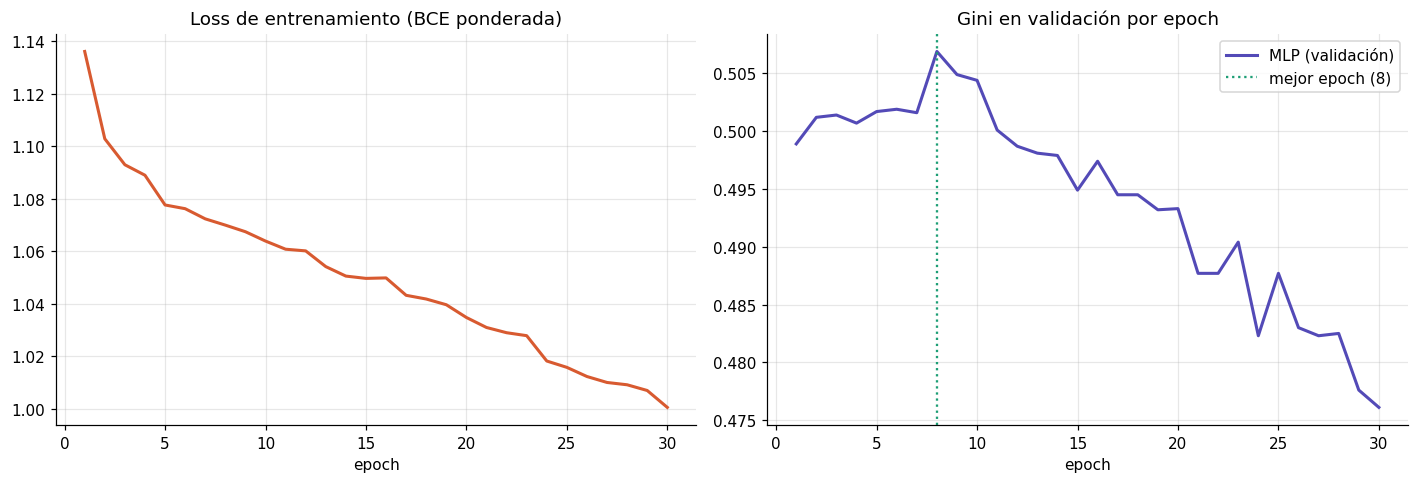

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, len(hist_nn['loss']) + 1), hist_nn['loss'], color='#D85A30', lw=2)
axes[0].set_title('Loss de entrenamiento (BCE ponderada)'); axes[0].set_xlabel('epoch')
axes[1].plot(range(1, len(hist_nn['val_gini']) + 1), hist_nn['val_gini'], color='#534AB7', lw=2, label='MLP (validación)')
axes[1].axvline(best_ep_nn, color='#1D9E75', ls=':', label=f'mejor epoch ({best_ep_nn})')
axes[1].set_title('Gini en validación por epoch'); axes[1].set_xlabel('epoch'); axes[1].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('reports/figures/dl_training_curves.png', dpi=150, bbox_inches='tight'); plt.show()

### Red neuronal tabular

**Gini test:** 0,508 (MLP) vs 0,518 (XGBoost), es decir −0,009.

**Convergencia y overfitting.** El mejor Gini en validación se alcanza en la epoch 8 (0,507).
Después la loss de entrenamiento sigue bajando, pero el Gini de validación cae hasta 0,476
en la epoch 30: un overfitting claro. Sin selección de epoch en un set separado, el resultado
habría dependido de cuándo se cortaba el entrenamiento, o se habría elegido mirando el test
(como en la versión anterior).

**Decisión.** La red no supera a XGBoost, es menos interpretable (no hay TreeSHAP exacto) y
es más inestable de entrenar. No hay argumento para usarla como champion.

## Capa 2 — LSTM sobre el historial de pagos

**Requiere:** `data/raw/installments_payments.csv` (pagos de créditos *anteriores* en Home
Credit, todos previos a la solicitud actual).

Por cliente se toman las últimas 12 cuotas, con dos variables por cuota:
- días de atraso (normalizados a meses);
- monto pagado / monto de la cuota.

El modelo es un LSTM bidireccional de 2 capas con atención.

In [4]:
from pathlib import Path
inst_path = Path('data/raw/installments_payments.csv')
LSTM_AVAILABLE = inst_path.exists()
SEQ_LEN = 12

if LSTM_AVAILABLE:
    inst = pd.read_csv(inst_path, usecols=['SK_ID_CURR', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT',
                                           'AMT_INSTALMENT', 'AMT_PAYMENT'])
    inst['atraso'] = ((inst['DAYS_ENTRY_PAYMENT'] - inst['DAYS_INSTALMENT']).clip(-365, 365) / 30).fillna(0)
    inst['ratio_pago'] = (inst['AMT_PAYMENT'] / inst['AMT_INSTALMENT'].replace(0, np.nan)).fillna(1).clip(0, 3)
    # últimas SEQ_LEN cuotas por cliente, de la más vieja a la más reciente
    inst = inst.sort_values(['SK_ID_CURR', 'DAYS_INSTALMENT'])
    inst = inst.groupby('SK_ID_CURR').tail(SEQ_LEN)
    inst['pos'] = inst.groupby('SK_ID_CURR').cumcount(ascending=False)   # 0 = más reciente

    ids = inst['SK_ID_CURR'].unique()
    id_to_row = pd.Series(np.arange(len(ids)), index=ids)
    seq = np.zeros((len(ids), SEQ_LEN, 2), dtype=np.float32)          # padding con ceros al inicio
    r = id_to_row[inst['SK_ID_CURR']].values
    t = SEQ_LEN - 1 - inst['pos'].values
    seq[r, t, 0] = inst['atraso'].values
    seq[r, t, 1] = inst['ratio_pago'].values

    raw_train = pd.read_parquet('data/processed/train.parquet')[['SK_ID_CURR', 'default']]
    raw_test  = pd.read_parquet('data/processed/test.parquet')[['SK_ID_CURR', 'default']]
    def secuencias(df):
        has = df['SK_ID_CURR'].isin(id_to_row.index).values
        Xs = np.zeros((len(df), SEQ_LEN, 2), dtype=np.float32)
        Xs[has] = seq[id_to_row[df.loc[has, 'SK_ID_CURR']].values]
        return torch.FloatTensor(Xs), has

    S_train, has_train = secuencias(raw_train)
    S_test,  has_test  = secuencias(raw_test)
    print(f'Clientes con historial — train: {has_train.mean():.1%} | test: {has_test.mean():.1%}')
else:
    print('installments_payments.csv no encontrado: se saltean las capas 2 y 3.')

Clientes con historial — train: 94.8% | test: 94.8%


In [5]:
if LSTM_AVAILABLE:
    class PaymentLSTM(nn.Module):
        def __init__(self, n_feat=2, hidden=64, layers=2, dropout=0.3):
            super().__init__()
            self.lstm = nn.LSTM(n_feat, hidden, layers, batch_first=True, bidirectional=True, dropout=dropout)
            self.attn = nn.Linear(hidden * 2, 1)
            self.head = nn.Sequential(nn.Linear(hidden * 2, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, 1))
        def forward(self, x):
            out, _ = self.lstm(x)
            w = torch.softmax(self.attn(out), dim=1)
            return torch.sigmoid(self.head((out * w).sum(dim=1))).squeeze(1)

    def train_lstm(epochs=12, batch_size=1024, lr=1e-3):
        fit_idx = splits['fit'][has_train[splits['fit']]]
        val_idx = splits['val'][has_train[splits['val']]]
        Xf, yf = S_train[fit_idx], torch.FloatTensor(y_train.values[fit_idx].astype(np.float32))
        Xv, yv = S_train[val_idx], y_train.values[val_idx]
        dl = DataLoader(TensorDataset(Xf, yf), batch_size=batch_size, shuffle=True)
        model = PaymentLSTM().to(DEVICE)
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
        pos_w = float((yf == 0).sum() / (yf == 1).sum())
        best, best_state = -1, None
        for ep in range(epochs):
            model.train()
            for xb, yb in dl:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                opt.zero_grad()
                w = torch.where(yb == 1, torch.full_like(yb, pos_w), torch.ones_like(yb))
                (nn.BCELoss(reduction='none')(model(xb), yb) * w).mean().backward()
                opt.step()
            g = gini(yv, predict(model, Xv))
            if g > best:
                best, best_ep, best_state = g, ep + 1, {k: v.clone() for k, v in model.state_dict().items()}
            print(f'  epoch {ep+1:2d} | Gini val {g:.4f} | best {best:.4f} (epoch {best_ep})')
        model.load_state_dict(best_state)
        return model, best_ep

    lstm_model, best_ep_lstm = train_lstm()
    lstm_test  = predict(lstm_model, S_test)
    lstm_train = predict(lstm_model, S_train)
    lstm_gini  = gini(y_test.values[has_test], lstm_test[has_test])
    xgb_gini_hist = gini(y_test.values[has_test], xgb_score[has_test])
    print(f'\nLSTM — Gini test (clientes con historial, n={has_test.sum():,}): {lstm_gini}')
    print(f'XGBoost en esos mismos clientes:                               {xgb_gini_hist}')

  epoch  1 | Gini val 0.1535 | best 0.1535 (epoch 1)
  epoch  2 | Gini val 0.1598 | best 0.1598 (epoch 2)
  epoch  3 | Gini val 0.1608 | best 0.1608 (epoch 3)
  epoch  4 | Gini val 0.1629 | best 0.1629 (epoch 4)
  epoch  5 | Gini val 0.1749 | best 0.1749 (epoch 5)
  epoch  6 | Gini val 0.1786 | best 0.1786 (epoch 6)
  epoch  7 | Gini val 0.1792 | best 0.1792 (epoch 7)
  epoch  8 | Gini val 0.1761 | best 0.1792 (epoch 7)
  epoch  9 | Gini val 0.1785 | best 0.1792 (epoch 7)
  epoch 10 | Gini val 0.1762 | best 0.1792 (epoch 7)
  epoch 11 | Gini val 0.1852 | best 0.1852 (epoch 11)
  epoch 12 | Gini val 0.1855 | best 0.1855 (epoch 12)

LSTM — Gini test (clientes con historial, n=58,321): 0.1868
XGBoost en esos mismos clientes:                               0.515


## Capa 3 — ¿La señal del LSTM es incremental?

Se combina el logit del score de XGBoost con el score del LSTM en una regresión logística
(stacking). El ajuste se hace en el split de calibración, que ninguno de los dos modelos vio,
y la evaluación en test. Si el Gini del stack supera al de XGBoost, el historial de pagos
aporta información que XGBoost no tiene.

In [6]:
if LSTM_AVAILABLE:
    logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
    def stack_features(xgb_p, lstm_p, has):
        return np.column_stack([logit(xgb_p), np.where(has, logit(lstm_p), 0.0), has.astype(float)])

    cal_idx = splits['cal']
    xgb_cal = scorer.raw_score(X_train.iloc[cal_idx])
    stack = LogisticRegression(C=1e6, max_iter=1000).fit(
        stack_features(xgb_cal, lstm_train[cal_idx], has_train[cal_idx]), y_train.values[cal_idx])
    stack_score = stack.predict_proba(stack_features(xgb_score, lstm_test, has_test))[:, 1]

    rng = np.random.default_rng(0)
    n = len(y_test); diffs = []
    yt = y_test.values
    for _ in range(200):
        i = rng.integers(0, n, n)
        diffs.append(gini(yt[i], stack_score[i]) - gini(yt[i], xgb_score[i]))
    stack_gini = gini(y_test, stack_score)
    print(f'Gini XGBoost:        {xgb_gini}')
    print(f'Gini XGBoost + LSTM: {stack_gini}  (Δ {stack_gini - xgb_gini:+.4f}, IC95% bootstrap '
          f'[{np.percentile(diffs, 2.5):+.4f}, {np.percentile(diffs, 97.5):+.4f}])')
    print(f'Coeficientes del stack (logit XGB, logit LSTM, tiene historial): {np.round(stack.coef_[0], 3)}')

Gini XGBoost:        0.5176
Gini XGBoost + LSTM: 0.5302  (Δ +0.0126, IC95% bootstrap [+0.0083, +0.0163])
Coeficientes del stack (logit XGB, logit LSTM, tiene historial): [0.914 0.779 0.182]


### LSTM y stacking

**El historial de pagos tiene señal, y es incremental.**
- **El LSTM solo** llega a un Gini de **0,187** en el 94,8% de los clientes con historial.
  Usa únicamente 2 variables por cuota (atraso y % pagado). Es bajo frente a 0,515 de
  XGBoost en esos mismos clientes, pero no es la comparación relevante.
- **La pregunta relevante es si aporta algo que XGBoost no tiene.** El stack (logística sobre
  el logit de XGBoost, el logit del LSTM y un indicador de historial, ajustada en el split de
  calibración) llega a **Gini 0,530 en test**:
  - +0,013 sobre XGBoost, con IC 95% bootstrap de **[+0,008; +0,016]**: no incluye al cero;
  - el coeficiente del LSTM es 0,78, comparable al de XGBoost (0,91).

**Lectura.** `application_train` describe al cliente en la foto de la solicitud. Las cuotas
de créditos anteriores describen cómo pagó. Son fuentes complementarias, y es la mejora más
grande de todo el proyecto. Apunta al mismo lugar que el análisis de errores (notebook 03):
falta información de comportamiento.

**Cuidados antes de llevarlo a producción:**
- **Re-validar** el stack completo: es un modelo nuevo. Calibración, master scale y fairness
  hay que correrlos de nuevo.
- **Ruteo:** el 5% sin historial queda sólo con XGBoost. Hay que vigilar la performance de
  ese segmento por separado.
- **Alternativa más simple:** features agregadas de `installments_payments` (atraso medio y
  máximo, % de cuotas pagadas a tiempo) dentro de XGBoost. Habría que compararla con el LSTM
  antes de asumir que hace falta la complejidad de una red recurrente.

> **Seguimiento.** Comparación hecha en el challenger M2 (`reports/challengers.json`): 11
> variables agregadas de `installments_payments` dentro de XGBoost llegan a **Gini 0,534**,
> igual o mejor que el stack con LSTM (0,530), sin red recurrente. Se recomienda la versión
> monotónica (M3, 0,528).

## Capa 4 — Autoencoder para detectar clientes atípicos

Se entrena sólo con buenos pagadores del split *fit*. El umbral de anomalía es el percentil
95 del error de reconstrucción en los buenos pagadores de *validación*. Si funcionara, los
clientes "atípicos" irían a revisión manual en lugar de a una decisión automática.

In [7]:
class CreditAutoencoder(nn.Module):
    def __init__(self, d, latent=32):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, latent))
        self.dec = nn.Sequential(nn.Linear(latent, 64), nn.ReLU(), nn.Linear(64, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Linear(128, d))
    def forward(self, x):
        return self.dec(self.enc(x))

def rec_error(model, X_t, bs=8192):
    model.eval()
    with torch.no_grad():
        return np.concatenate([((model(X_t[i:i+bs].to(DEVICE)) - X_t[i:i+bs].to(DEVICE)) ** 2).mean(1).cpu().numpy()
                               for i in range(0, len(X_t), bs)])

X_good = to_tensor(X_fit[y_fit.values == 0])
ae = CreditAutoencoder(X_fit.shape[1]).to(DEVICE)
opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
dl = DataLoader(TensorDataset(X_good), batch_size=1024, shuffle=True)
for ep in range(20):
    ae.train()
    for (xb,) in dl:
        xb = xb.to(DEVICE); opt.zero_grad()
        nn.MSELoss()(ae(xb), xb).backward(); opt.step()

umbral = np.percentile(rec_error(ae, to_tensor(X_val[y_val.values == 0])), 95)
err_test = rec_error(ae, to_tensor(X_test))
atip = err_test > umbral
yt = y_test.values
print(f'Atípicos en test: {atip.mean():.1%}')
print(f'Default — atípicos: {yt[atip].mean():.2%} | típicos: {yt[~atip].mean():.2%} | ratio {yt[atip].mean()/yt[~atip].mean():.2f}x')
print(f'Gini XGBoost — atípicos: {gini(yt[atip], xgb_score[atip])} | típicos: {gini(yt[~atip], xgb_score[~atip])}')

Atípicos en test: 5.0%
Default — atípicos: 8.69% | típicos: 8.04% | ratio 1.08x
Gini XGBoost — atípicos: 0.4863 | típicos: 0.5195


### Autoencoder

**El autoencoder no sirve como filtro de revisión manual.** Marca al 5% de los clientes como
atípicos, pero su tasa de default es casi igual a la del resto: 8,7% vs 8,0% (1,08x). El Gini
de XGBoost en ese grupo cae algo (0,486 vs 0,520), pero mandar a revisión manual un 5% que no
es más riesgoso ni mucho peor ordenado no justifica el costo operativo.

Es un resultado negativo y se reporta como tal. La señal de "baja confianza" que sí funciona
es la incertidumbre por MC Dropout (notebook 07, parte 2).

## Comparativa final

In [8]:
filas = [
    {'modelo': 'XGBoost (champion)', 'gini_test': xgb_gini, 'población': 'todos'},
    {'modelo': 'Red neuronal tabular', 'gini_test': nn_gini, 'población': 'todos'},
    {'modelo': 'Ensemble XGB + MLP (promedio)', 'gini_test': gini(y_test, (xgb_score + nn_score) / 2), 'población': 'todos'},
]
if LSTM_AVAILABLE:
    filas += [
        {'modelo': 'LSTM (historial de pagos)', 'gini_test': lstm_gini, 'población': f'con historial ({has_test.mean():.0%})'},
        {'modelo': 'Stack XGBoost + LSTM', 'gini_test': stack_gini, 'población': 'todos'},
    ]
comparativa = pd.DataFrame(filas)
display(comparativa)

import os
os.makedirs('models/dl', exist_ok=True)
torch.save(nn_model.state_dict(), 'models/dl/tabular_nn.pt')
torch.save(ae.state_dict(), 'models/dl/autoencoder.pt')
meta = {
    'evaluation': 'test set; epochs elegidas en validación; stacking ajustado en calibración',
    'xgboost_gini': xgb_gini,
    'tabular_nn': {'gini': nn_gini, 'best_epoch': best_ep_nn, 'architecture': [256, 128, 64], 'dropout': 0.3},
    'ensemble_xgb_nn': {'gini': gini(y_test, (xgb_score + nn_score) / 2), 'method': 'simple_average'},
    'autoencoder': {'pct_flagged': float(atip.mean()), 'default_rate_atipicos': float(yt[atip].mean()),
                    'default_rate_tipicos': float(yt[~atip].mean())},
}
if LSTM_AVAILABLE:
    torch.save(lstm_model.state_dict(), 'models/dl/lstm_payments.pt')
    meta['lstm'] = {'gini_with_history': lstm_gini, 'coverage_test': float(has_test.mean()),
                    'xgboost_gini_same_clients': xgb_gini_hist, 'best_epoch': best_ep_lstm}
    meta['stack_xgb_lstm'] = {'gini': stack_gini, 'delta_vs_xgb': round(stack_gini - xgb_gini, 4),
                              'delta_ci95': [round(float(np.percentile(diffs, 2.5)), 4),
                                             round(float(np.percentile(diffs, 97.5)), 4)]}
with open('models/dl/dl_metadata.json', 'w') as f:
    json.dump(meta, f, indent=2)
with open('reports/dashboard/dl_metadata.json', 'w') as f:
    json.dump(meta, f, indent=2)

,modelo,gini_test,población
0,XGBoost (champion),0.5176,todos
1,Red neuronal tabular,0.5082,todos
2,Ensemble XGB + MLP (promedio),0.5201,todos
3,LSTM (historial de pagos),0.1868,con historial (95%)
4,Stack XGBoost + LSTM,0.5302,todos


## Decisión de gobernanza

| Modelo | Gini test | Decisión |
|---|---:|---|
| **XGBoost + Platt** | **0,518** | Champion actual |
| Red neuronal tabular | 0,508 | Descartada: no supera al champion y sobreajusta |
| Ensemble XGBoost + MLP | 0,520 | Descartado: +0,002 no compensa mantener dos modelos |
| LSTM (sólo historial) | 0,187 | No sirve sola |
| **Stack XGBoost + LSTM** | **0,530** | **Challenger recomendado** (+0,013, IC 95% excluye 0) |
| Autoencoder | — | Descartado como filtro |

**Recomendación al comité de modelos.**
1. Mantener XGBoost como champion.
2. Desarrollar el stack XGBoost + LSTM como **challenger formal**, con validación completa.
3. Antes, evaluar si features agregadas de pagos dentro de XGBoost capturan la misma mejora
   con menos complejidad.

El deep learning se justifica sólo donde explota información que el modelo tabular no ve,
como la secuencia de pagos. No se justifica como reemplazo genérico de XGBoost sobre las
mismas features.